# 09 - LR head on the single splits (and the matching bar chart)

`run_split` in notebooks 02/03 only read out the **NN** head, so fine-tune + LR exists for the
5-fold CV but not for the 80/10/10 and 70/15/15 splits. This notebook fills that gap **without
retraining**: the best-epoch weights (`best_weights`) were saved for every split/depth, so we
rebuild each fine-tuned backbone, re-extract features, and fit the LR head.

Convention: LR is fit on all non-test subjects (train $+$ val), matching `run_cv`, which fits LR on
the whole training fold including the inner-validation subjects. Results are cached to
`lr_split_results.json` so the chart can be redrawn instantly afterwards.

**Cost:** inference only (no training). Roughly a few minutes per configuration for tiny and longer
for base; 12 configurations total.

In [1]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
import sys, json, math
import numpy as np, torch
import torch.nn as nn, torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
sys.path.insert(0, '/Users/faenegoro/Documents/Neuroimaging/BrainOmni')
from brainomni.model import BrainOmni

import random
def set_seed(seed=123):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed(123)

device = torch.device('mps') if torch.backends.mps.is_available() else torch.device('cpu')
SAVE_DIR = '../data/preprocessed'
OUT      = '../results_withseed'
CKPT_ROOT = '/Users/faenegoro/Documents/Neuroimaging/BrainOmni/ckpt_collection'
labels = np.load(os.path.join(SAVE_DIR, 'labels.npy')); N = len(labels)
FROZEN_CV, HANDCRAFT_CV = 0.831, 0.872
NF = [10, 9, 8]
DEPTH_LABELS = ['Last 1 block', 'Last 2 blocks', 'Last 3 blocks']
print('Device:', device, '| N =', N)

W0818 01:14:36.503000 32070 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Device: mps | N = 148


In [2]:
class FinetuneClassifier(nn.Module):
    """Must match the definition in notebooks 02/03 so load_state_dict lines up."""
    def __init__(self, encoder_blocks, hidden_dim):
        super().__init__()
        self.blocks = encoder_blocks
        self.head = nn.Sequential(
            nn.Linear(hidden_dim * 16, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 2))
    def forward(self, x1, x2):
        x1, x2 = x1.to(device), x2.to(device)
        for block in self.blocks:
            x1 = block(x1); x2 = block(x2)
        x1 = F.normalize(x1, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        x2 = F.normalize(x2, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        return self.head(((x1 + x2) / 2).flatten(1))

def load_model_bundle(tag, sfx):
    cfg = json.load(open(f'{CKPT_ROOT}/{tag}/model_cfg.json'))
    ckpt = torch.load(f'{CKPT_ROOT}/{tag}/BrainOmni.pt', map_location='cpu', weights_only=True)
    p1 = np.load(os.path.join(SAVE_DIR, f'proj_out1{sfx}.npy'))
    p2 = np.load(os.path.join(SAVE_DIR, f'proj_out2{sfx}.npy'))
    return cfg, ckpt, p1, p2

def fresh_frozen_model(cfg, ckpt):
    m = BrainOmni(**cfg); m.load_state_dict(ckpt, strict=False)
    for p in m.parameters(): p.requires_grad = False
    return m.to(device).eval()

def extract_features(model, ft_blocks, n_frozen, p1, p2):
    """All subjects through frozen blocks then the fine-tuned blocks -> (N, 16*D)."""
    feats = []
    with torch.no_grad():
        for i in range(N):
            x1 = torch.tensor(p1[i]).unsqueeze(0).to(device)
            x2 = torch.tensor(p2[i]).unsqueeze(0).to(device)
            for b in list(model.blocks)[:n_frozen]:
                x1 = b(x1); x2 = b(x2)
            for b in ft_blocks:
                x1 = b(x1); x2 = b(x2)
            x1 = F.normalize(x1, p=2.0, dim=-1, eps=1e-6).mean(dim=2).flatten(1)
            x2 = F.normalize(x2, p=2.0, dim=-1, eps=1e-6).mean(dim=2).flatten(1)
            feats.append(((x1 + x2) / 2).squeeze(0).cpu().numpy())
    return np.array(feats)
print('Helpers ready.')

Helpers ready.


In [3]:
# Rebuild each fine-tuned backbone from saved weights and fit the LR head. Inference only.
import time
CACHE = os.path.join(OUT, 'lr_split_results.json')
results = json.load(open(CACHE)) if os.path.exists(CACHE) else {}

MODELS = [('tiny', '', 256, 'BrainOmni-tiny'), ('base', '_base', 512, 'BrainOmni-base')]
for tag, sfx, hdim, name in MODELS:
    path = f'{OUT}/finetune_shared{sfx}.pt'
    if not os.path.exists(path):
        print(f'skip {tag}: {path} not found'); continue
    d = torch.load(path, map_location='cpu', weights_only=False)
    ns, splits = d['nn_split'], d['splits']
    if not ns:
        print(f'skip {tag}: no split results saved'); continue
    cfg, ckpt, p1, p2 = load_model_bundle(tag, sfx)
    results.setdefault(tag, {})
    for sname in ns:
        results[tag].setdefault(sname, {})
        tr, va, te = [np.asarray(a) for a in splits[sname]]
        fit_idx = np.concatenate([tr, va])          # all non-test subjects, matches run_cv
        for nf in NF:
            key = str(nf)
            if key in results[tag][sname]:
                print(f'{tag} {sname} last-{11-nf}: cached ({results[tag][sname][key]:.3f})'); continue
            t0 = time.time()
            model = fresh_frozen_model(cfg, ckpt)
            unfrozen = nn.ModuleList(list(model.blocks)[nf:-1])
            ft = FinetuneClassifier(unfrozen, hdim).to(device)
            ft.load_state_dict(ns[sname][nf]['best_weights'])
            ft.eval()
            feats = extract_features(model, ft.blocks, nf, p1, p2)
            lr = LogisticRegression(max_iter=1000).fit(feats[fit_idx], labels[fit_idx])
            acc = accuracy_score(labels[te], lr.predict(feats[te]))
            results[tag][sname][key] = float(acc)
            json.dump(results, open(CACHE, 'w'), indent=1)
            print(f'{tag} {sname} last-{11-nf}: LR {acc:.3f}  ({(time.time()-t0)/60:.1f} min)', flush=True)
print('\nDone. Cached to', CACHE)

/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


tiny 80/10/10 last-1: LR 0.800  (0.1 min)


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


tiny 80/10/10 last-2: LR 0.800  (0.1 min)


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


tiny 80/10/10 last-3: LR 0.800  (0.1 min)


... (14 outputs left out)

/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


base 70/15/15 last-2: LR 0.826  (0.3 min)


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


base 70/15/15 last-3: LR 0.870  (0.3 min)

Done. Cached to ../results_withseed/lr_split_results.json


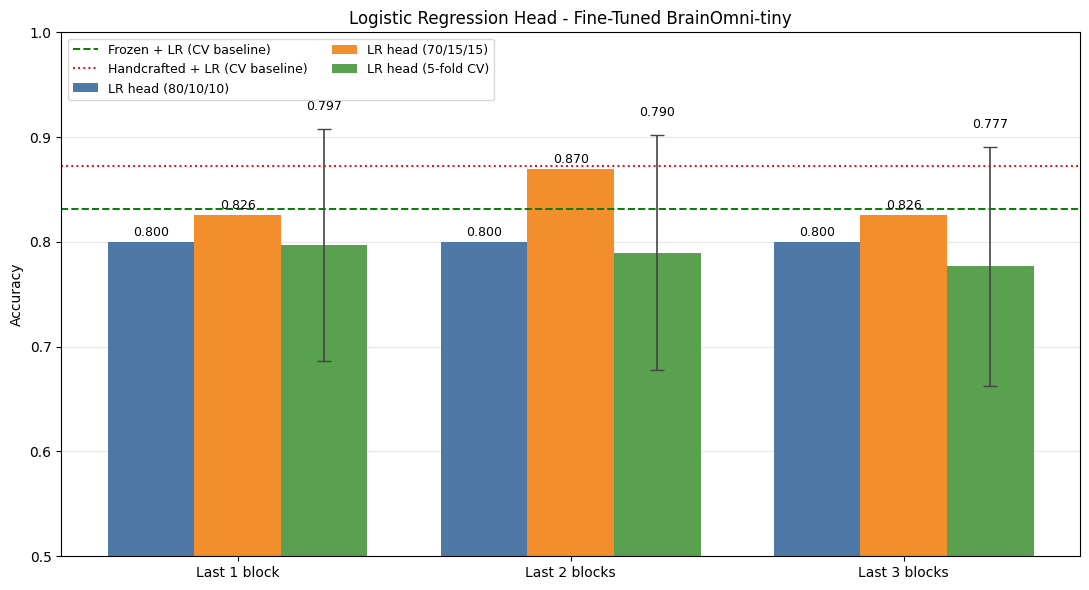

Saved head_lr_tiny.png | 80/10/10 [0.8, 0.8, 0.8] | 70/15/15 [0.826, 0.87, 0.826] | CV [0.797, 0.79, 0.777]


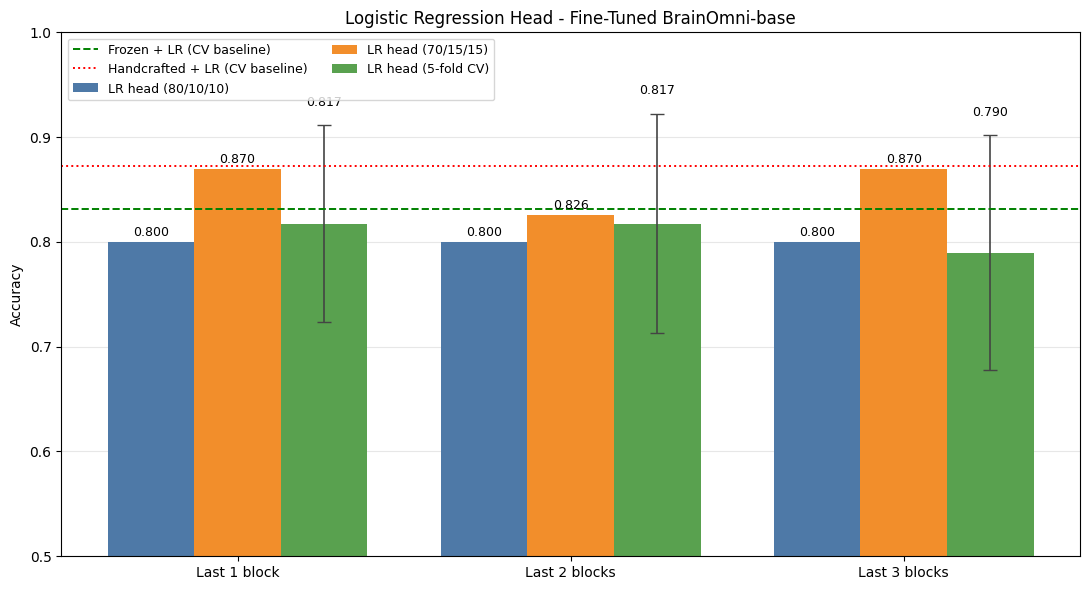

Saved head_lr_base.png | 80/10/10 [0.8, 0.8, 0.8] | 70/15/15 [0.87, 0.826, 0.87] | CV [0.817, 0.817, 0.79]


In [4]:
# LR-head chart, same layout as the NN chart in notebook 08
def chart_lr(tag, sfx, name, fname):
    d = torch.load(f'{OUT}/finetune_shared{sfx}.pt', map_location='cpu', weights_only=False)
    cv = d['cv']
    v80 = [results[tag]['80/10/10'][str(nf)] for nf in NF]
    v70 = [results[tag]['70/15/15'][str(nf)] for nf in NF]
    vcv = [cv[nf]['lr_mean'] for nf in NF]
    ecv = [np.std(cv[nf]['lr_folds']) for nf in NF]

    x = np.arange(3); w = 0.26
    fig, ax = plt.subplots(figsize=(11, 6))
    b1 = ax.bar(x - w, v80, w, color='#4E79A7', label='LR head (80/10/10)')
    b2 = ax.bar(x,     v70, w, color='#F28E2B', label='LR head (70/15/15)')
    b3 = ax.bar(x + w, vcv, w, yerr=ecv, capsize=5, color='#59A14F',
                error_kw=dict(lw=1.2, ecolor='#444'), label='LR head (5-fold CV)')
    ax.bar_label(b1, fmt='%.3f', fontsize=9, padding=2)
    ax.bar_label(b2, fmt='%.3f', fontsize=9, padding=2)
    ax.bar_label(b3, fmt='%.3f', fontsize=9, padding=12)
    ax.axhline(FROZEN_CV,    color='green', ls='--', lw=1.4, label='Frozen + LR (CV baseline)')
    ax.axhline(HANDCRAFT_CV, color='red',   ls=':',  lw=1.4, label='Handcrafted + LR (CV baseline)')
    ax.set_xticks(x); ax.set_xticklabels(DEPTH_LABELS)
    ax.set_ylabel('Accuracy'); ax.set_ylim(0.5, 1.0)
    ax.set_title(f'Logistic Regression Head - Fine-Tuned {name}')
    ax.legend(fontsize=9, ncol=2, loc='upper left'); ax.grid(axis='y', alpha=0.3); ax.set_axisbelow(True)
    plt.tight_layout(); plt.savefig(os.path.join(OUT, fname), dpi=150); plt.show()
    print('Saved', fname, '| 80/10/10', [round(v,3) for v in v80],
          '| 70/15/15', [round(v,3) for v in v70], '| CV', [round(v,3) for v in vcv])

for tag, sfx, hdim, name in MODELS:
    if tag in results and len(results[tag].get('80/10/10', {})) == 3:
        chart_lr(tag, sfx, name, f'head_lr_{tag}.png')
    else:
        print(f'skip chart for {tag}: run the previous cell first')